# AF3 – Simulación numérica e interpretación del comportamiento dinámico
**Modelado y Simulación de Sistemas Mecatrónicos**

**Integrantes del equipo**

| Nombre | Matrícula |
|---|---|
| Emiliano Medina Vega | 2226680 |
| Fernando Israel Álvarez Garza | 2142565 |
| Angel Saul Orona Arvizu | 2226978 |
| Víctor Eduardo Castañeda Castro | 2226650 |
| Braulio Hernández Muñoz | 2226514 |

---

## Modelo del péndulo-robot

Ecuación característica obtenida con el formalismo Euler-Lagrange (con par del motor y fricción de la articulación):

$$\tau = \left[m l_c^2 + I_r\right]\ddot q + m g l_c \sin(q) + b\,\dot q + f_c\,\mathrm{signo}(\dot q)$$

No se considera fricción estática, porque no se proporciona ese parámetro.

**Espacio de estados**, con $x_1=q$ y $x_2=\dot q$:

$$\dot x_1 = x_2,\qquad \dot x_2 = \frac{1}{m l_c^2 + I_r}\Big[\tau - m g l_c \sin(x_1) - b\,x_2 - f_c\,\mathrm{signo}(x_2)\Big]$$

**Condiciones iniciales:** $x_1(0)=0$, $x_2(0)=0$.

**Par aplicado:** $\tau(t) = 1.5\,\sin(t)$ N·m. **Tiempo de simulación:** 10 s.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parámetros del péndulo-robot
Ir = 0.16    # momento de inercia [kg m^2]
m  = 5       # masa de todo el mecanismo [kg]
g  = 9.81    # gravedad [m/s^2]
lc = 0.01    # distancia al centro de masa [m]
b  = 0.14    # coeficiente de viscosidad [N m s/rad]
fc = 0.45    # coeficiente de fricción de Coulomb [N m]

M  = m*lc**2 + Ir           # inercia total: m lc^2 + Ir = 0.1605

def signo(v):
    # signo(v) ~ tanh(100000 v): suaviza la discontinuidad en v = 0
    return np.tanh(100000*v)

def tau(t):
    return 1.5*np.sin(t)    # par del motor [N m]

In [ ]:
def pendulo(t, x):
    q  = x[0]               # x1: posición articular
    qp = x[1]               # x2: velocidad articular
    qpp = (tau(t) - b*qp - fc*signo(qp) - m*g*lc*np.sin(q)) / M
    return [qp, qpp]        # [x1', x2']

In [ ]:
# Simulación de 0 a 10 s con x(0) = [0, 0]
ti, tf, h = 0, 10, 0.0025
ts = np.arange(ti, tf + h, h)
sol = solve_ivp(pendulo, [ti, tf], [0, 0], method='RK45',
                rtol=1e-3, max_step=h, t_eval=ts)
t, q, qp = sol.t, sol.y[0], sol.y[1]

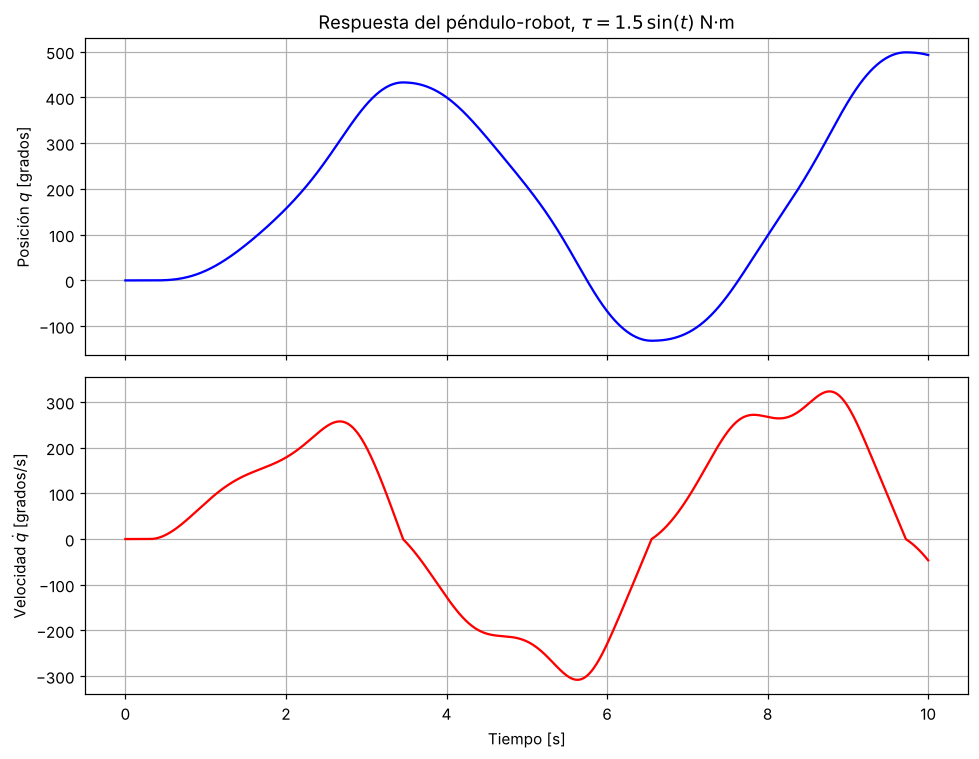

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax[0].plot(t, np.degrees(q), 'b')
ax[0].set_ylabel('Posición $q$ [grados]'); ax[0].grid(True)
ax[0].set_title(r'Respuesta del péndulo-robot, $\tau = 1.5\,\sin(t)$ N·m')
ax[1].plot(t, np.degrees(qp), 'r')
ax[1].set_ylabel(r'Velocidad $\dot{q}$ [grados/s]'); ax[1].set_xlabel('Tiempo [s]'); ax[1].grid(True)
plt.tight_layout(); plt.show()

q(10) = 492.8 grados,  qp(10) = -46.5 grados/s


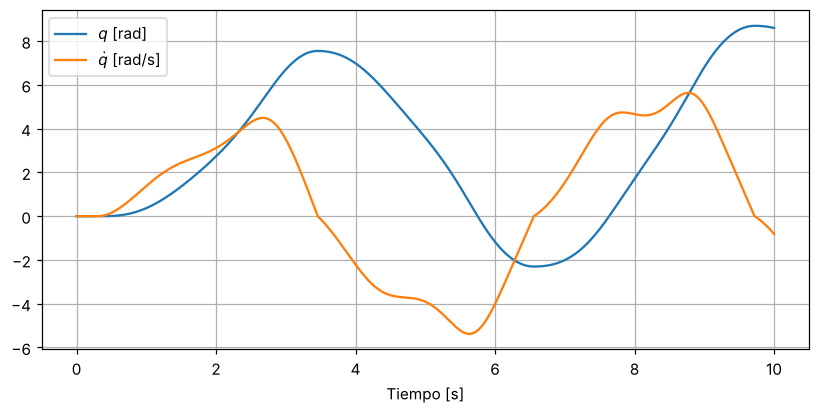

In [ ]:
# Posición y velocidad en rad y rad/s
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t, q, label='$q$ [rad]'); ax.plot(t, qp, label=r'$\dot{q}$ [rad/s]')
ax.set_xlabel('Tiempo [s]'); ax.grid(True); ax.legend(); plt.show()
print(f"q(10) = {np.degrees(q[-1]):.1f} grados,  qp(10) = {np.degrees(qp[-1]):.1f} grados/s")